Координаты ФЭУ:
[[-1.91159624  0.34792069  0.47407912]
 [ 0.83719441 -0.29619373  1.79203091]
 [ 0.33805721  1.91619039 -0.46252752]
 [ 1.95265861 -0.02545003 -0.43182944]
 [ 1.72079502  0.83821533  0.57987892]
 [ 1.1848776  -1.59839744 -0.20295485]
 [-0.0917473   1.43371825  1.39141453]
 [-0.48253883  0.8826405   1.72861274]
 [-0.294951    1.9615656   0.25546877]
 [-0.55124745 -0.41068104 -1.8781553 ]
 [ 1.8379164  -0.31186817  0.72443188]
 [-0.83197665  0.11412895 -1.81515549]
 [ 0.62064162  0.52621182  1.82699346]
 [-0.49700801  1.8571839  -0.55122682]
 [ 1.48487524 -1.29974551  0.32528008]
 [ 1.81887265 -0.70199341 -0.44599049]
 [-0.87855988  1.67649603  0.64613745]
 [-1.99892605  0.04528431  0.04737059]
 [-0.70133557 -1.65318832  0.88039582]
 [-1.97744486  0.29882875 -0.02032773]
 [ 0.01135277  1.99994723  0.00906497]
 [-0.97667771 -1.68785363  0.44412922]
 [ 0.2800872  -1.58614204  1.18562414]
 [ 0.95620689  0.26117143  1.73708315]
 [ 1.74682913  0.5782275   0.78373525]
 [-0.6137

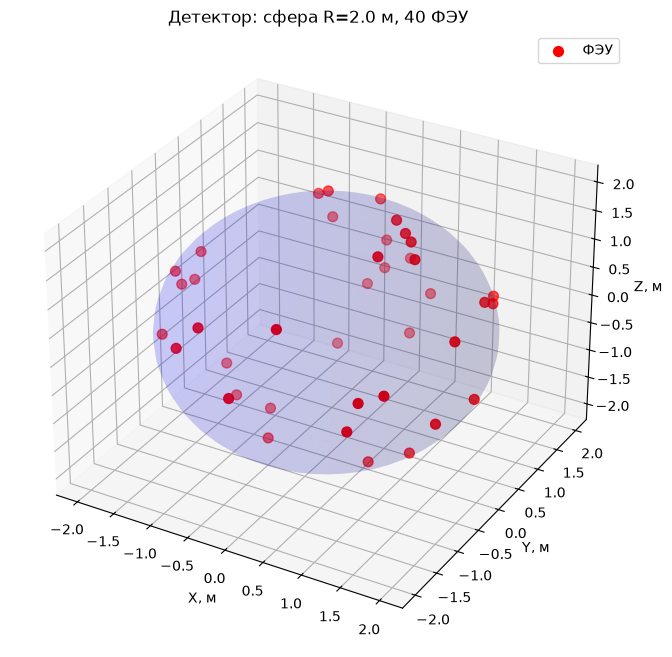

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmt_positions = self._generate_pmt_positions()

    def _generate_pmt_positions(self):
        phi = np.random.uniform(0, 2 * np.pi, self.N)
        cosTheta = np.random.uniform(-1, 1, self.N)
        sinTheta = np.sqrt(1 - cosTheta ** 2)
        x = self.R * sinTheta * np.cos(phi)
        y = self.R * sinTheta * np.sin(phi)
        z = self.R * cosTheta
        return np.column_stack([x, y, z])

    def contains_point(self, point):
        point = np.asarray(point, dtype=float)
        distances = np.linalg.norm(self.pmt_positions - point, axis=1)
        min_dist = np.min(distances)
        if min_dist <= self.r:
            return int(np.argmin(distances))
        return -1

    def visualize(self):
        fig = plt.figure(figsize=(8, 8))
        ax = fig.add_subplot(111, projection='3d')

        u = np.linspace(0, 2 * np.pi, 50)
        v = np.linspace(0, np.pi, 50)
        x = self.R * np.outer(np.cos(u), np.sin(v))
        y = self.R * np.outer(np.sin(u), np.sin(v))
        z = self.R * np.outer(np.ones(np.size(u)), np.cos(v))
        ax.plot_surface(x, y, z, color='b', alpha=0.1, edgecolor='none')

        ax.scatter(self.pmt_positions[:, 0],
                   self.pmt_positions[:, 1],
                   self.pmt_positions[:, 2],
                   color='red', s=50, label='ФЭУ')

        ax.set_xlabel('X, м')
        ax.set_ylabel('Y, м')
        ax.set_zlabel('Z, м')
        ax.set_title(f'Детектор: сфера R={self.R} м, {self.N} ФЭУ')
        ax.legend()
        plt.show()



det = Detector(R=2.0, N=40, r=0.1, a=0.5)
print("Координаты ФЭУ:")
print(det.pmt_positions[:40])

test_point = det.pmt_positions[5]
idx = det.contains_point(test_point)
if idx == -1:
    print(f"Точка {test_point}: не попал в ФЭУ")
else:
    print(f"Точка {test_point}: попал в ФЭУ номер {idx}")

test_point2 = np.array([0, 0, 1])
idx2 = det.contains_point(test_point2)
if idx2 == -1:
    print(f"Точка {test_point2}: не попал в ФЭУ")
else:
    print(f"Точка {test_point2}: попал в ФЭУ номер {idx2}")

det.visualize()